# P10 — Crop theo vùng Otsu đề xuất

Thí nghiệm mới trên nền **T02B_D4_R50**. Chưa huấn luyện. Rủi ro cần quan sát: Otsu không phải mask tổn thương chuẩn; crop có thể cắt mất tổn thương. Kiểm kỹ trước khi train.

Giữ split, seed42, ResNet50/ImageNet V1, D4 train, CE không trọng số, AdamW 1e-4, batch32, tối đa16 epoch, patience4. Chỉ thêm phép tiền xử lý hiện tại; áp cho train và validation, trước D4/normalize. Không dùng test để chọn phương án. P04–SoG đã có lượt lịch sử, không nằm trong chín notebook mới.

## 1. Cấu hình
Gắn hai Input: gói mã v1.1 đã giải nén và dataset ảnh ISIC cũ. Chọn T4; bật Internet để tải ImageNet V1. Không tự cài phiên bản mới hay thay môi trường khi kiểm tra báo STOP.

In [1]:
from pathlib import Path
import sys, json, hashlib, importlib
# Điền đường dẫn thư mục ảnh nhìn thấy trong Input Kaggle.
IMAGE_ROOT = None
# Để None nếu chỉ gắn một bản gói v1.1; nếu có nhiều bản, điền đường dẫn chính xác.
BUNDLE_ROOT = None
METHOD = 'P10'
RUN_TRAIN = True  # Lượt đầu: chỉ kiểm tra và tạo gallery.
RUN_TEST = False   # Luôn giữ False trong đợt thăm dò này.
REVIEW_CSV = None  # Sau khi xem ảnh: đường dẫn CSV quan sát đã điền.
EXPECTED_MANIFEST_SHA = 'ecf6608c7b28760a8d6491ecbb0bdb5bb015219440c60eacb2443ac33c358bf7'
assert RUN_TEST is False
assert METHOD == 'P10', 'Dùng notebook riêng tương ứng; không đổi METHOD ở đây.'


In [2]:
from pathlib import Path

# Tìm thư mục chứa đủ 8 thư mục lớp.
labels = {"MEL", "NV", "BCC", "AK", "BKL", "DF", "VASC", "SCC"}

image_roots = sorted({
    p.parent
    for p in Path("/kaggle/input").rglob("MEL")
    if p.is_dir()
    and all((p.parent / label).is_dir() for label in labels)
})

print("Số thư mục ảnh tìm thấy:", len(image_roots))
for path in image_roots:
    print(path)

if len(image_roots) == 1:
    IMAGE_ROOT = str(image_roots[0])
    print("\nĐã đặt IMAGE_ROOT =", IMAGE_ROOT)
else:
    print("\nChưa tự chọn đường dẫn. Gửi CHA kết quả cell này.")

Số thư mục ảnh tìm thấy: 1
/kaggle/input/datasets/salviohexia/isic-2019-skin-lesion-images-for-classification

Đã đặt IMAGE_ROOT = /kaggle/input/datasets/salviohexia/isic-2019-skin-lesion-images-for-classification


## 2. Kiểm đúng gói nguồn
Notebook nhỏ gọi mã dùng chung trong Input; không cần checkpoint T02B để train. Các dự đoán đối chứng và manifest đã có trong gói.

In [3]:
def file_sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
if BUNDLE_ROOT is None:
    candidates = [p.parent for p in Path('/kaggle/input').rglob('bundle_hashes.json')
                  if file_sha(p) == EXPECTED_MANIFEST_SHA]
    assert len(candidates) == 1, 'Cần đúng một gói v1.1 đã giải nén; hoặc đặt BUNDLE_ROOT.'
    BUNDLE_ROOT = candidates[0]
BUNDLE_ROOT = Path(BUNDLE_ROOT).resolve()
assert file_sha(BUNDLE_ROOT/'bundle_hashes.json') == EXPECTED_MANIFEST_SHA
for name, expected in json.loads((BUNDLE_ROOT/'bundle_hashes.json').read_text()).items():
    assert file_sha(BUNDLE_ROOT/name) == expected, 'Sai file: '+name
assert IMAGE_ROOT is not None, 'Điền IMAGE_ROOT là thư mục dataset ảnh ISIC trong Input.'
assert Path(IMAGE_ROOT).is_dir(), 'IMAGE_ROOT không tồn tại.'
sys.path.insert(0, str(BUNDLE_ROOT))
for module_name in ['runner', 'preprocess_original', 'locked_functions']:
    old = sys.modules.get(module_name)
    if old is not None:
        assert Path(old.__file__).resolve().parent == BUNDLE_ROOT, 'Restart kernel để tránh dùng module của gói khác.'
import runner
importlib.reload(runner)
assert Path(runner.__file__).resolve() == BUNDLE_ROOT/'runner.py'
print('Gói đã khớp hash. Phương án:', METHOD, '| RUN_TRAIN:', RUN_TRAIN)


Gói đã khớp hash. Phương án: P10 | RUN_TRAIN: True


In [4]:
from pathlib import Path

review_files = sorted(
    Path("/kaggle/input").rglob(f"{METHOD}_visual_review_CHA.csv")
)

assert len(review_files) == 1, (
    f"Cần đúng một file review cho {METHOD}: {review_files}"
)

REVIEW_CSV = str(review_files[0])
print("File review:", REVIEW_CSV)

File review: /kaggle/input/datasets/nguyentuanduc15/p01-p10-train-review-20261023/P10_visual_review_CHA.csv


## 3. Kiểm thử hoặc huấn luyện
RUN_TRAIN=False: kiểm ảnh, môi trường, khởi tạo, D4/loader, forward/backward và tạo gallery. Không cập nhật model.

Sau khi quan sát ảnh thật, điền CSV review theo README. Khi train, khởi tạo mới từ ImageNet; không nối tiếp model T02B. Mọi lỗi giữ output và dừng.

In [5]:
result = runner.run(BUNDLE_ROOT, IMAGE_ROOT, METHOD, RUN_TRAIN, REVIEW_CSV)
print(result)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 193MB/s]


P10 epoch 01: train=0.8752, val=0.8092, F1=0.4565
P10 epoch 02: train=0.6822, val=0.7358, F1=0.5139
P10 epoch 03: train=0.5991, val=0.7581, F1=0.5407
P10 epoch 04: train=0.5247, val=0.7257, F1=0.5396
P10 epoch 05: train=0.4474, val=0.7833, F1=0.5485
P10 epoch 06: train=0.3873, val=0.8060, F1=0.5763
P10 epoch 07: train=0.3305, val=0.8398, F1=0.5837
P10 epoch 08: train=0.2652, val=0.8103, F1=0.5663
P10 epoch 09: train=0.2180, val=0.8615, F1=0.5763
P10 epoch 10: train=0.1731, val=0.9215, F1=0.5895
P10 epoch 11: train=0.1260, val=0.9538, F1=0.5759
P10 epoch 12: train=0.0976, val=0.9687, F1=0.5758
P10 epoch 13: train=0.0740, val=0.9617, F1=0.5849
P10 epoch 14: train=0.0613, val=0.9863, F1=0.5780
FULL output và ZIP: /kaggle/working/P10_R50_P10_20261023_154113_532890 /kaggle/working/P10_R50_P10_20261023_154113_532890.zip
{'output': '/kaggle/working/P10_R50_P10_20261023_154113_532890', 'status': 'TRAIN_COMPLETED_VALIDATION_CHECKED', 'result': {'method': 'P10', 'lock_sha': 'cc8739196e9d0a908e61

## 4. Xem kết quả kiểm tra ảnh
Mỗi trang có ảnh gốc, resize nền T02B, phương án mới và mask/crop đề xuất. Gallery chỉ lấy train. Mask không phải nhãn phân đoạn chuẩn.

,split,label_name,fallback,changed_fraction,mean_abs_change
0,train,AK,0.751227,0.102760,1.711366
1,train,BCC,0.676495,0.223247,3.932461
2,train,BKL,0.598267,0.337365,7.038526
3,train,DF,0.620321,0.307229,4.151805
4,train,MEL,0.534612,0.363072,9.958369
5,train,NV,0.413904,0.552639,12.721489
6,train,SCC,0.702407,0.196280,3.580639
7,train,VASC,0.430464,0.522581,13.067376
8,val,AK,0.785714,0.125321,2.411589
9,val,BCC,0.683908,0.234263,4.295572


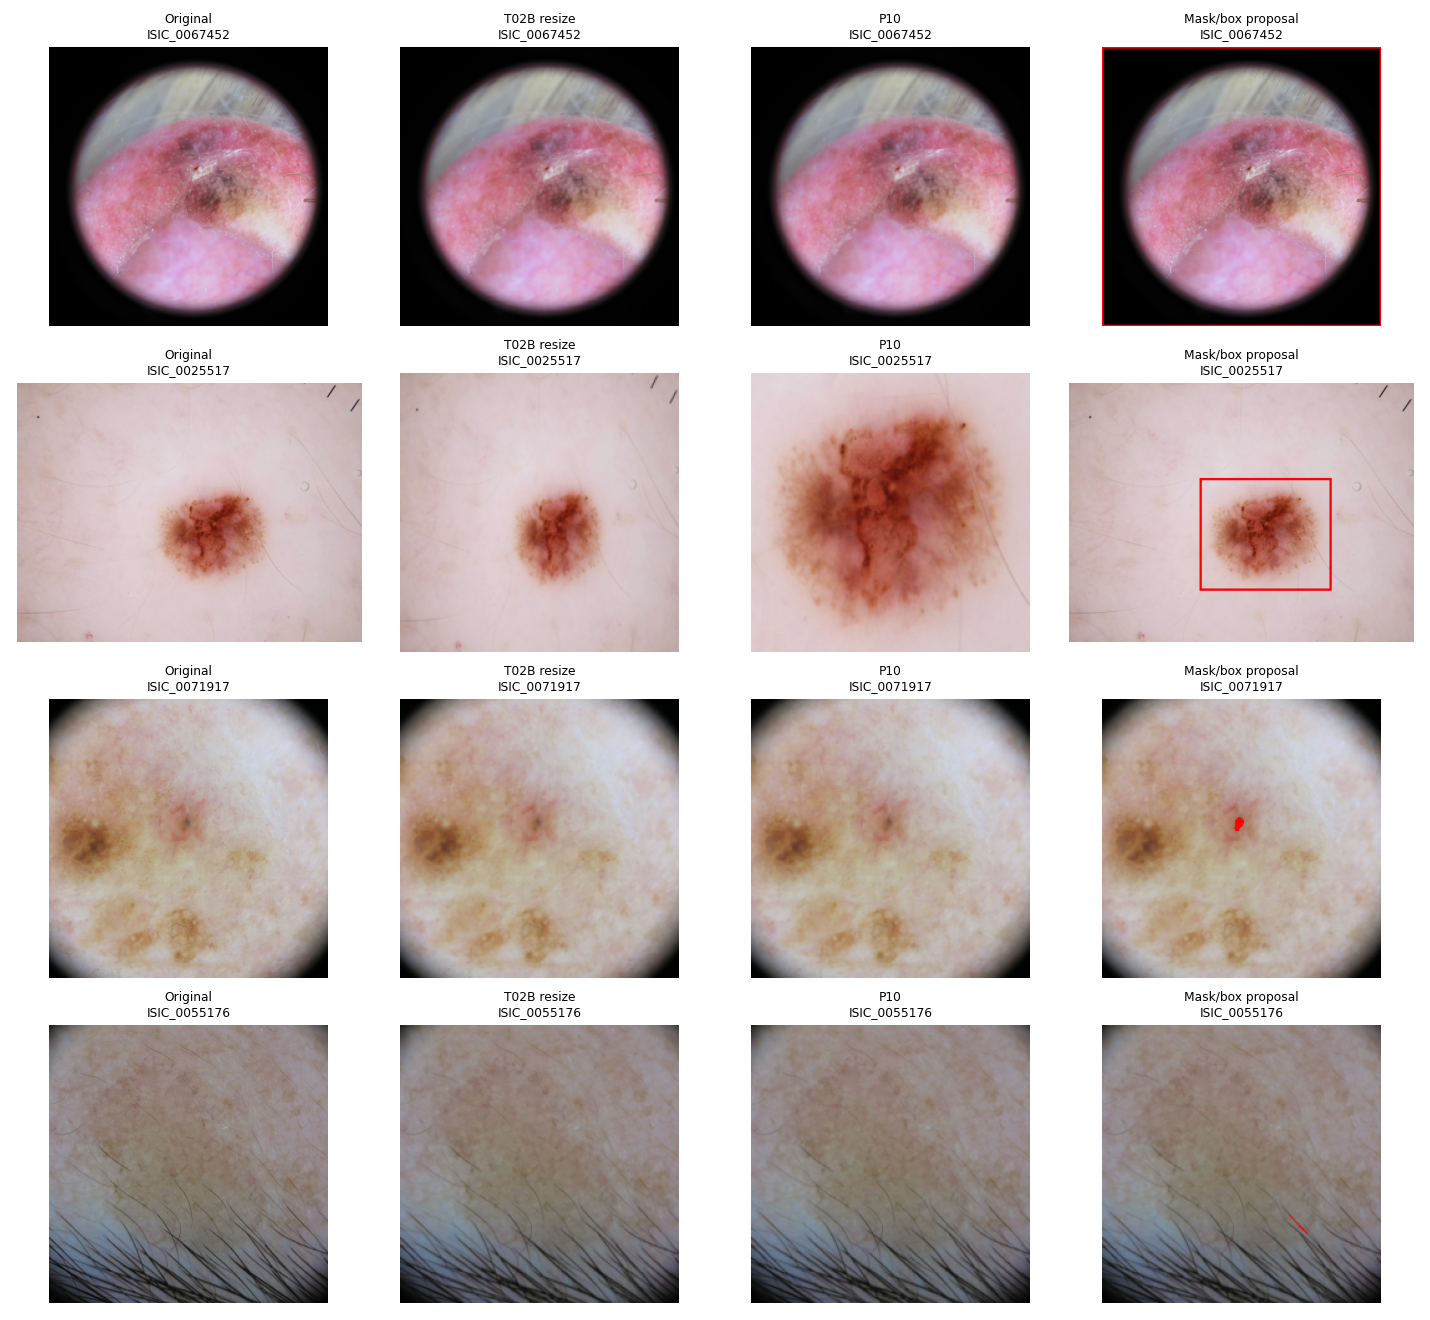

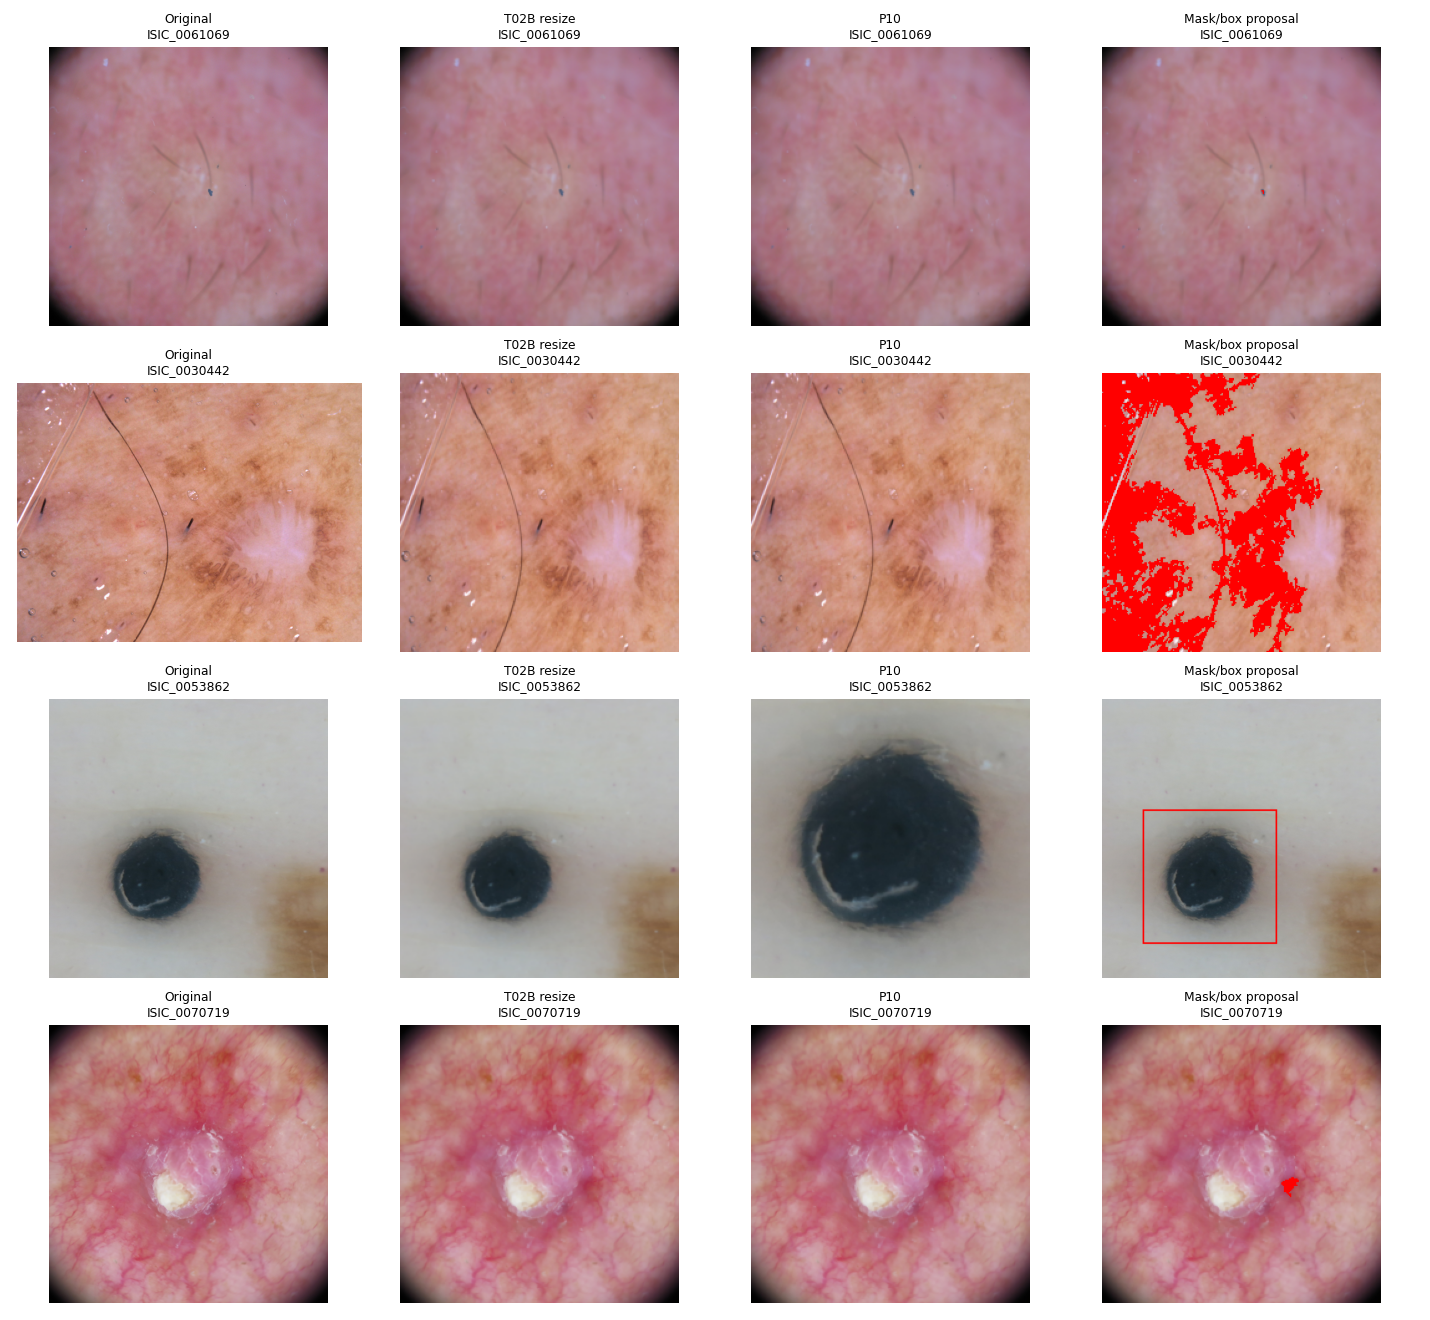

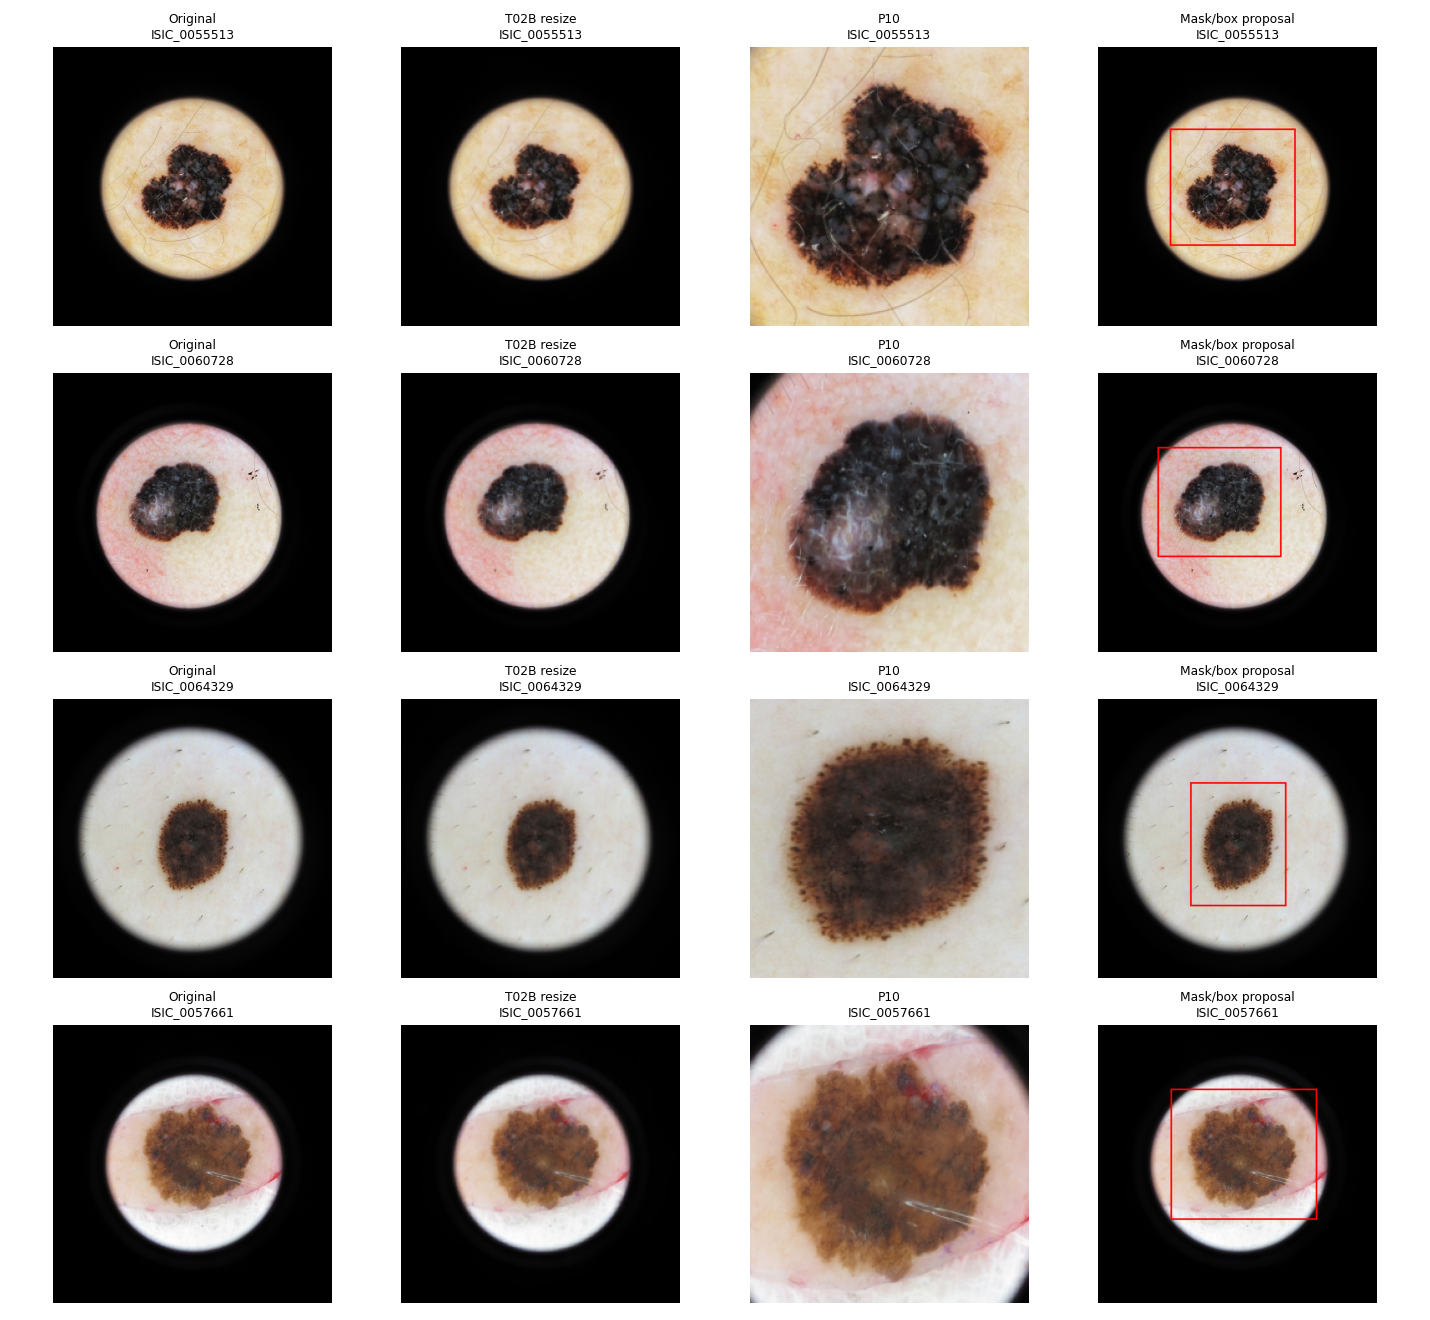

,candidate,reference,delta_macro_f1_pp,ci95_low_pp,ci95_high_pp,n_boot,contains_zero
0,P10,T02B,-1.35104,-5.446651,3.083793,2000,True


Tải FULL ZIP: /kaggle/working/P10_R50_P10_20261023_154113_532890.zip


In [6]:
from IPython.display import display, Image as DisplayImage
import pandas as pd
output = Path(result['output'])
display(pd.read_csv(output/'transform_summary.csv'))
for image_path in sorted(output.glob('gallery_*.png')):
    display(DisplayImage(filename=str(image_path)))
if (output/'comparison.csv').exists():
    display(pd.read_csv(output/'comparison.csv'))
print('Tải FULL ZIP:', output.with_suffix('.zip'))

## 5. Đọc kết quả và gửi CHA
Gửi notebook đã chạy và ZIP output. Lượt kiểm tra còn cần quan sát thị giác, không tự coi là đã đủ điều kiện train. Sau train, đọc macro-F1, balanced accuracy, từng lớp, confusion matrix và CI; một seed chưa chứng minh phương án luôn tốt hơn. Giữ cả các kết quả không cải thiện.